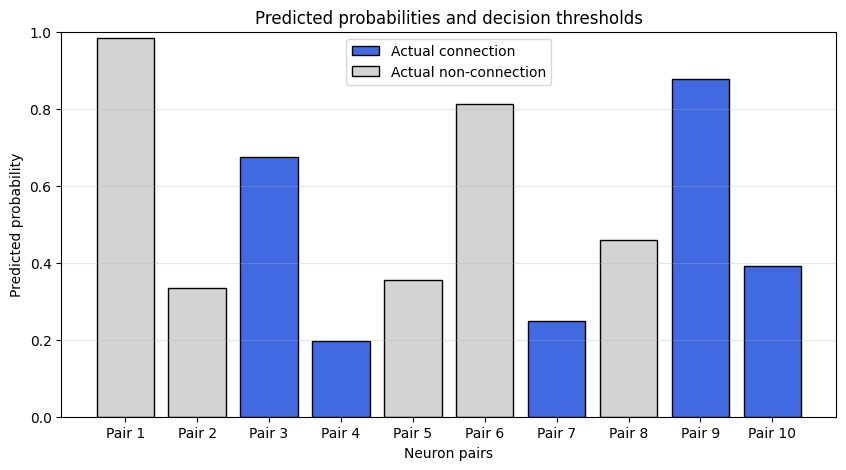

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# ==========================================================
# 1. Génération aléatoire des données
# ==========================================================

np.random.seed(56)   # Pour reproduire toujours le même exemple
n_pairs = 10         # Nombre de paires de neurones

# Probabilités prédites aléatoires entre 0 et 1
p_hat = np.random.rand(n_pairs)

# Vérité terrain aléatoire :
# 1 = connexion réelle, 0 = non connexion réelle
A_true = np.random.randint(0, 2, size=n_pairs)

# Seuils à tester
#thresholds = [0.25, 0.75]
#thresholds = np.arange(0, 1.05, 0.01)
thresholds = []

# Labels des paires
pairs = [f"Pair {i+1}" for i in range(n_pairs)]

# Couleurs :
# bleu = vraie connexion
# gris = vraie non connexion
colors = ["royalblue" if a == 1 else "lightgray" for a in A_true]

# ==========================================================
# 2. Affichage des probabilités avec les seuils
# ==========================================================

x = np.arange(n_pairs)

plt.figure(figsize=(10, 5))
plt.bar(x, p_hat, color=colors, edgecolor="black")

# Lignes de seuil
for tau in thresholds:
    plt.axhline(
        tau,
        linestyle="--",
        linewidth=2,
        label=fr"Threshold $\tau = {tau}$"
    )

# Légende des couleurs
legend_elements = [
    Patch(facecolor="royalblue", edgecolor="black",
          label="Actual connection"),
    Patch(facecolor="lightgray", edgecolor="black",
          label="Actual non-connection")
]

# Ajouter la légende des couleurs + seuils
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles=legend_elements + handles)

plt.xticks(x, pairs)
plt.ylim(0, 1)
plt.xlabel("Neuron pairs")
plt.ylabel("Predicted probability")
plt.title("Predicted probabilities and decision thresholds")
plt.grid(axis="y", alpha=0.3)
if len(thresholds) < 10:
    plt.show()
else:
    plt.close()

# ==========================================================
# 3. Confusion matrix pour chaque seuil
# ==========================================================

for tau in thresholds:

    # Prédiction binaire
    A_pred = (p_hat >= tau).astype(int)

    # Matrice de confusion
    cm = confusion_matrix(A_true, A_pred, labels=[1, 0])

    # Affichage
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Connection", "No Connection"]
    )

    disp.plot(cmap="Blues")
    plt.title(f"Confusion Matrix for Threshold τ = {tau}")
    if len(thresholds) < 10:
        plt.show()
    else:
        plt.close()

    # Extraction TN, FP, FN, TP
    TN, FP, FN, TP = cm.ravel()

    # Calcul TPR et FPR
    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
    FPR = FP / (FP + TN) if (FP + TN) > 0 else 0

    print(f"\n===== Threshold τ = {tau} =====")
    print(f"TP = {TP}, FP = {FP}, TN = {TN}, FN = {FN}")
    print(f"TPR = {TPR:.3f}")
    print(f"FPR = {FPR:.3f}")

In [8]:
# ==========================================================
# 3. Confusion matrix pour chaque seuil
# ==========================================================
roc_points = []

for tau in thresholds:

    # Prédiction binaire
    A_pred = (p_hat >= tau).astype(int)

    # Matrice de confusion
    cm = confusion_matrix(A_true, A_pred)

    # Affichage
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No connection", "Connection"]
    )

    disp.plot(cmap="Blues")
    plt.title(f"Confusion Matrix for Threshold τ = {tau}")
    if len(thresholds) < 10:
        plt.show()
    else:
        plt.close()

    # Extraction TN, FP, FN, TP
    TN, FP, FN, TP = cm.ravel()

    # ======================================================
    # 4. Calcul des métriques
    # ======================================================

    # True Positive Rate (Recall / Sensitivity)
    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0

    # False Negative Rate
    FNR = FN / (TP + FN) if (TP + FN) > 0 else 0

    # False Positive Rate
    FPR = FP / (FP + TN) if (FP + TN) > 0 else 0

    # True Negative Rate (Specificity)
    TNR = TN / (FP + TN) if (FP + TN) > 0 else 0

    roc_points.append((FPR, TPR, tau))

    # ======================================================
    # 5. Affichage des résultats
    # ======================================================

    print(f"\n===== Threshold τ = {tau} =====")
    #print(f"TP = {TP}, FP = {FP}, TN = {TN}, FN = {FN}")

    print(f"True Positive Rate (TPR) = {TP:.3f} / ({TP:.3f} + {FN:.3f}) = {TPR:.3f}")
    print(f"False Positive Rate (FPR) = {FP:.3f} / ({FP:.3f} + {TN:.3f}) = {FPR:.3f}")


===== Threshold τ = 0.0 =====
True Positive Rate (TPR) = 5.000 / (5.000 + 0.000) = 1.000
False Positive Rate (FPR) = 5.000 / (5.000 + 0.000) = 1.000

===== Threshold τ = 0.01 =====
True Positive Rate (TPR) = 5.000 / (5.000 + 0.000) = 1.000
False Positive Rate (FPR) = 5.000 / (5.000 + 0.000) = 1.000

===== Threshold τ = 0.02 =====
True Positive Rate (TPR) = 5.000 / (5.000 + 0.000) = 1.000
False Positive Rate (FPR) = 5.000 / (5.000 + 0.000) = 1.000

===== Threshold τ = 0.03 =====
True Positive Rate (TPR) = 5.000 / (5.000 + 0.000) = 1.000
False Positive Rate (FPR) = 5.000 / (5.000 + 0.000) = 1.000

===== Threshold τ = 0.04 =====
True Positive Rate (TPR) = 5.000 / (5.000 + 0.000) = 1.000
False Positive Rate (FPR) = 5.000 / (5.000 + 0.000) = 1.000

===== Threshold τ = 0.05 =====
True Positive Rate (TPR) = 5.000 / (5.000 + 0.000) = 1.000
False Positive Rate (FPR) = 5.000 / (5.000 + 0.000) = 1.000

===== Threshold τ = 0.06 =====
True Positive Rate (TPR) = 5.000 / (5.000 + 0.000) = 1.000
Fals

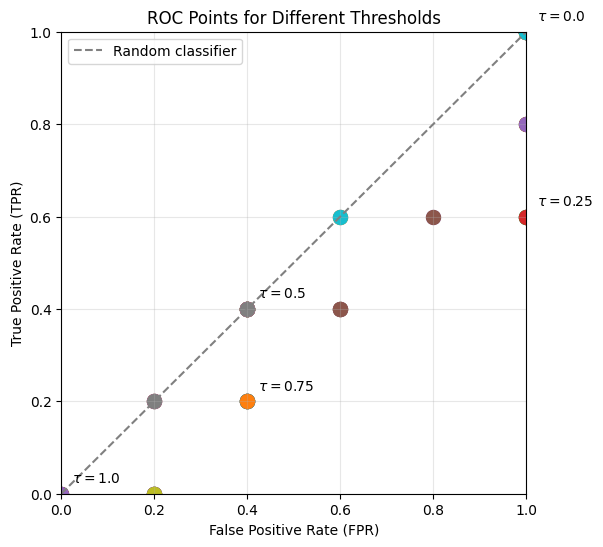

In [9]:
# ==========================================================
# 6. Plot des points ROC correspondant aux thresholds testés
# ==========================================================

roc_points = []

for tau in thresholds:

    # Prédiction binaire
    A_pred = (p_hat >= tau).astype(int)

    # Matrice de confusion
    cm = confusion_matrix(A_true, A_pred)

    # Extraction TN, FP, FN, TP
    TN, FP, FN, TP = cm.ravel()

    # Calcul des métriques
    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
    FPR = FP / (FP + TN) if (FP + TN) > 0 else 0

    # Stockage du point ROC
    roc_points.append((FPR, TPR, tau))

# ==========================================================
# 7. Affichage de la courbe ROC avec annotation des thresholds
# ==========================================================

plt.figure(figsize=(6, 6))

# Diagonale du classificateur aléatoire
plt.plot([0, 1], [0, 1], linestyle="--", color="gray",
         label="Random classifier")

# Affichage des points ROC
for FPR, TPR, tau in roc_points:
    if len(roc_points) < 3 or tau in [0, 0.25, 0.5, 0.75, 1]:
        plt.scatter(FPR, TPR, s=100)
        plt.annotate(
            fr"$\tau = {tau}$",
            (FPR, TPR),
            textcoords="offset points",
            xytext=(8, 8)
        )
    else:
        plt.scatter(FPR, TPR, s=100)

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Points for Different Thresholds")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

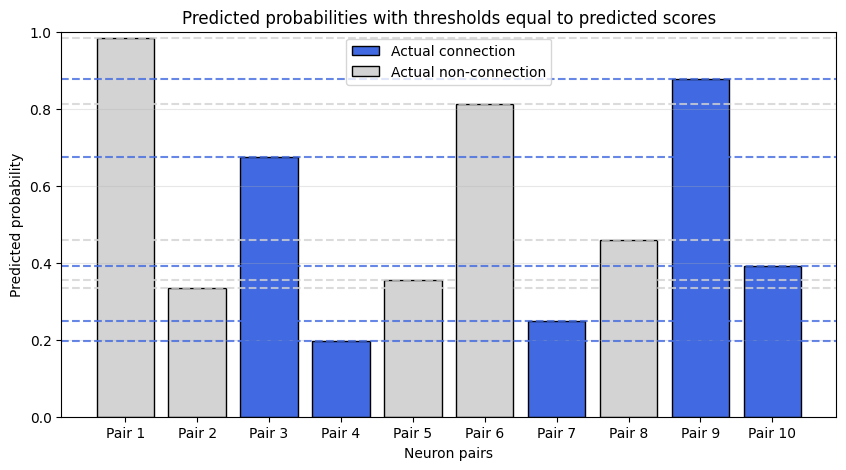

In [2]:
# ==========================================================
# 2. Affichage des probabilités avec les seuils exacts
# ==========================================================

x = np.arange(n_pairs)

plt.figure(figsize=(10, 5))
plt.bar(x, p_hat, color=colors, edgecolor="black")

for tau, color in zip(p_hat, colors):
    plt.axhline(
        tau,
        linestyle="--",
        linewidth=1.5,
        color=color,
        alpha=0.8
    )

legend_elements = [
    Patch(facecolor="royalblue", edgecolor="black",
          label="Actual connection"),
    Patch(facecolor="lightgray", edgecolor="black",
          label="Actual non-connection")
]

plt.legend(handles=legend_elements)

plt.xticks(x, pairs)
plt.ylim(0, 1)
plt.xlabel("Neuron pairs")
plt.ylabel("Predicted probability")
plt.title("Predicted probabilities with thresholds equal to predicted scores")
plt.grid(axis="y", alpha=0.3)
plt.show()

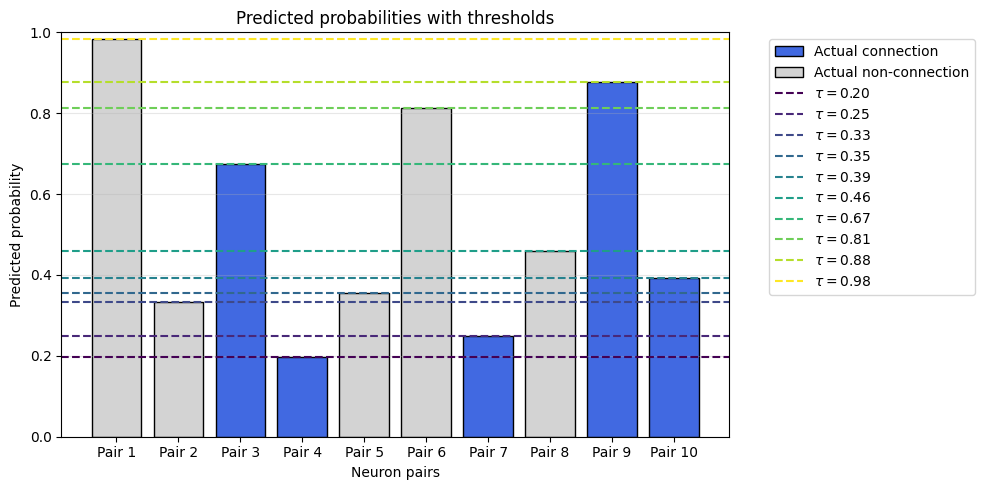

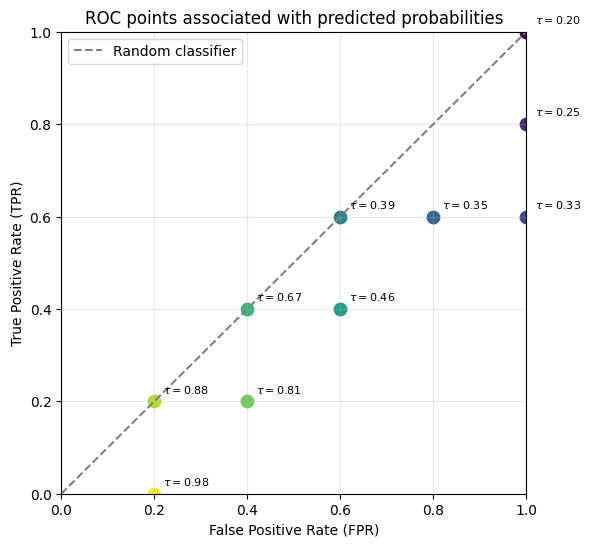

In [3]:
# Seuils exactement égaux aux probabilités prédites
thresholds = np.sort(p_hat)

# Couleur différente pour chaque threshold
threshold_colors = plt.cm.viridis(np.linspace(0, 1, len(thresholds)))

# ==========================================================
# Graphe des probabilités + thresholds
# ==========================================================

x = np.arange(n_pairs)

plt.figure(figsize=(10, 5))
plt.bar(x, p_hat, color=colors, edgecolor="black")

for tau, c in zip(thresholds, threshold_colors):
    plt.axhline(
        tau,
        linestyle="--",
        linewidth=1.5,
        color=c,
        label=fr"$\tau={tau:.2f}$"
    )

legend_elements = [
    Patch(facecolor="royalblue", edgecolor="black", label="Actual connection"),
    Patch(facecolor="lightgray", edgecolor="black", label="Actual non-connection")
]

handles, labels = plt.gca().get_legend_handles_labels()

plt.legend(
    handles=legend_elements + handles,
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.xticks(x, pairs)
plt.ylim(0, 1)
plt.xlabel("Neuron pairs")
plt.ylabel("Predicted probability")
plt.title("Predicted probabilities with thresholds")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================================
# ROC points avec les mêmes couleurs que les thresholds
# ==========================================================

roc_points = []

for tau in thresholds:
    A_pred = (p_hat >= tau).astype(int)

    cm = confusion_matrix(A_true, A_pred, labels=[0, 1])
    TN, FP, FN, TP = cm.ravel()

    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
    FPR = FP / (FP + TN) if (FP + TN) > 0 else 0

    roc_points.append((FPR, TPR, tau))

plt.figure(figsize=(6, 6))

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")

for (FPR, TPR, tau), c in zip(roc_points, threshold_colors):
    plt.scatter(FPR, TPR, color=c, s=80)
    plt.annotate(
        fr"$\tau={tau:.2f}$",
        (FPR, TPR),
        textcoords="offset points",
        xytext=(6, 6),
        fontsize=8
    )

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC points associated with predicted probabilities")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()